In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn

plt.rcParams["font.sans-serif"] = ["SimHei", "WenQuanYi Zen Hei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False  # 解决负号 '-' 显示为方块的问题
plt.rcParams["font.size"] = 12  # 可以适当调整字体大小

## Free test

In [2]:
# 计算给定查询的前 k 个最相关文档。
def compute_relevance_scores(query_embeddings, document_embeddings):
    """
    计算给定查询的前 k 个最相关文档。

    参数:
    query_embeddings: 表示查询嵌入的张量 (tensor),形状: [seq_len, d_model]
    document_embeddings: 表示 k 个文档嵌入的张量,形状: [k, max_sql_len, d_model]

    返回: 基于相关性分数排序的文档索引
    """

    # 注: 假设 document_embeddings 已经进行了适当的填充并转移到 GPU

    # 1. 计算查询嵌入和文档嵌入的批量点积
    # scores = torch.matmul(query_embeddings.unsqueeze(0), document_embeddings.transpose(1, 2))
    scores = torch.einsum("sd, kmd -> ksm", query_embeddings, document_embeddings)
    print("scores shape:", scores.shape)  # 输出形状应为 [k, seq_len, max_sql_len]

    # 2. 在文档词语维度上应用最大池化,找出每个查询词语的最大相似度
    max_scores_per_query_term = scores.max(dim=2).values
    print(
        "max_scores_per_query_term shape:", max_scores_per_query_term.shape
    )  # 输出形状应为 [k, seq_len]

    # 3. 对查询词语的分数求和,得到每个文档的总分
    total_scores = max_scores_per_query_term.sum(dim=1)
    print("total_scores shape:", total_scores.shape)  # 输出形状应为 [k]

    # 4. 根据总分对文档进行降序排序
    sorted_indices = total_scores.argsort(descending=True)

    return sorted_indices


# 测试代码
if __name__ == "__main__":
    # 设置随机种子以保证结果可复现
    torch.manual_seed(42)

    # 模拟输入数据
    num_queries = 5  # 查询中的词数
    embedding_dim = 768  # 假设使用BERT-base的嵌入维度
    num_documents = 3  # 测试用文档数量
    max_doc_length = 10  # 文档的最大长度

    # 随机生成查询和文档嵌入
    query_embeddings = torch.randn(num_queries, embedding_dim)
    document_embeddings = torch.randn(num_documents, max_doc_length, embedding_dim)

    # 计算相关性分数
    relevance_scores = compute_relevance_scores(query_embeddings, document_embeddings)

    print("相关性分数:", relevance_scores)

    # 根据相关性分数对文档进行排序
    sorted_indices = relevance_scores.argsort(descending=True)
    print("按相关性分数降序排列的文档索引:", sorted_indices)

scores shape: torch.Size([3, 5, 10])
max_scores_per_query_term shape: torch.Size([3, 5])
total_scores shape: torch.Size([3])
相关性分数: tensor([2, 1, 0])
按相关性分数降序排列的文档索引: tensor([0, 1, 2])


原始矩阵 A_original 形状: (100, 80)
原始矩阵 A_original 的秩 (理论上，实际计算可能因噪声而接近满秩): 80
------------------------------
U 矩阵形状: (100, 100)
奇异值向量 s 的长度: (80,)
Vh 矩阵形状: (80, 80)

前10个奇异值 (SVD能够揭示矩阵的“能量”或重要性):
[109.90166394   9.03435422   8.64246071   7.4005213    6.37460749
   1.79027831   1.73107576   1.69526368   1.67589908   1.62585253]
------------------------------
低秩近似矩阵 A_approx 的形状: (100, 80)
低秩近似矩阵 A_approx 的秩: 5
------------------------------
原始矩阵和低秩近似矩阵之间的误差 (Frobenius范数): 8.508398127095145


Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.


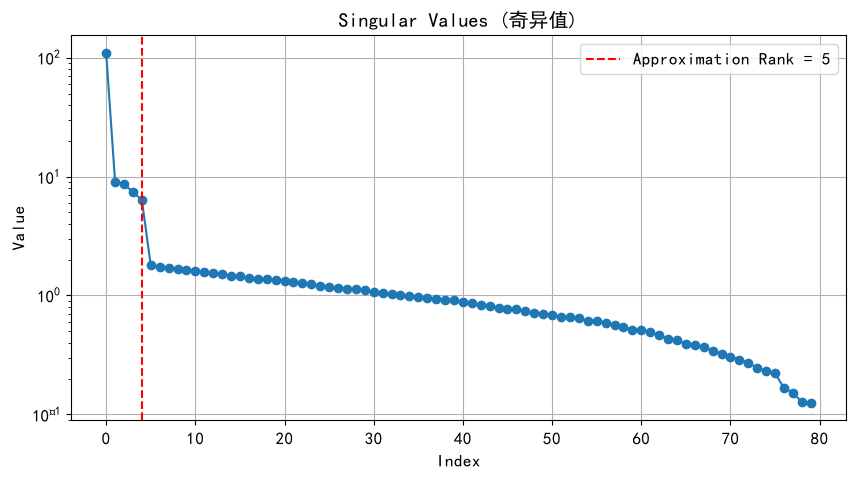


矩阵太大，不适合直接可视化为图像，请检查数值。

--- 关键点总结 ---
原始矩阵存储参数量: 8000
低秩近似矩阵存储参数量 (U_k, s_k, Vh_k): 905 (不包括额外的对角矩阵存储，如果只存向量的话)
当 rank_k (5) 远小于 M(100) 和 N(80) 时，参数量大大减少，实现了压缩。
例如，如果只存储 U_k 和 Vh_k，参数量为 (M+N)*approx_rank。
本例中：原始参数 8000 = 8000，近似参数 900 = 900


In [3]:
# --- 1. 创建一个示例的“高秩”矩阵 ---
# 我们可以创建一个 M x N 的矩阵
M, N = 100, 80
# 为了演示，我们先创建一个真实的低秩矩阵，然后加上一些噪声，使其变成一个“高秩”但可近似的矩阵
# 创建两个“瘦”矩阵，它们的乘积将是低秩的
rank_k = 5 # 假设真实秩为 5
U_true = np.random.rand(M, rank_k)
V_true = np.random.rand(N, rank_k)

# 真实的低秩矩阵
original_low_rank_matrix = np.dot(U_true, V_true.T)

# 加上一些随机噪声，使其变为一个“高秩”但有内在低秩结构的数据矩阵
noise = np.random.randn(M, N) * 0.1 # 噪音强度
A_original = original_low_rank_matrix + noise

print(f"原始矩阵 A_original 形状: {A_original.shape}")
print(f"原始矩阵 A_original 的秩 (理论上，实际计算可能因噪声而接近满秩): {np.linalg.matrix_rank(A_original)}")
print("-" * 30)

# --- 2. 使用奇异值分解 (SVD) 进行低秩分解 ---
# SVD 将矩阵 A 分解为 U * S * Vh
# U: 左奇异向量矩阵 (M x M)
# s: 奇异值向量 (min(M, N) 长度)
# Vh: 右奇异向量的共轭转置矩阵 (N x N)
U, s, Vh = np.linalg.svd(A_original)

print(f"U 矩阵形状: {U.shape}")
print(f"奇异值向量 s 的长度: {s.shape}")
print(f"Vh 矩阵形状: {Vh.shape}")
print("\n前10个奇异值 (SVD能够揭示矩阵的“能量”或重要性):")
print(s[:10])
print("-" * 30)

# --- 3. 通过截断 SVD 实现低秩近似 ---
# 我们选择一个比原始矩阵秩小得多的 k，来近似原矩阵
approx_rank = 5 # 我们希望用秩为5的矩阵来近似

approx_rank = min(approx_rank, len(s)) # 确保不超过奇异值数量

# 提取前 k 个奇异值、左奇异向量和右奇异向量
U_k = U[:, :approx_rank]
s_k = np.diag(s[:approx_rank]) # 将奇异值向量转换为对角矩阵
Vh_k = Vh[:approx_rank, :]

# 重构低秩近似矩阵 A_approx
# A_approx = U_k * s_k * Vh_k
A_approx = np.dot(U_k, np.dot(s_k, Vh_k))

print(f"低秩近似矩阵 A_approx 的形状: {A_approx.shape}")
print(f"低秩近似矩阵 A_approx 的秩: {np.linalg.matrix_rank(A_approx)}") # 理论上是 approx_rank
print("-" * 30)

# --- 4. 比较原始矩阵和低秩近似矩阵 ---
# 计算近似误差（Frobenius范数）
approximation_error = np.linalg.norm(A_original - A_approx, 'fro')
print(f"原始矩阵和低秩近似矩阵之间的误差 (Frobenius范数): {approximation_error}")

# 可视化前几个奇异值，可以看到它们衰减得很快，这正是低秩矩阵的特征
plt.figure(figsize=(10, 5))
plt.plot(s, 'o-')
plt.title('Singular Values (奇异值)')
plt.xlabel('Index')
plt.ylabel('Value')
plt.grid(True)
plt.axvline(x=approx_rank - 1, color='r', linestyle='--', label=f'Approximation Rank = {approx_rank}')
plt.legend()
plt.yscale('log') # 奇异值通常呈指数衰减，用对数坐标更清晰
plt.show()

# 进一步可视化，展示原始矩阵和近似矩阵的差异（如果矩阵足够小，可以显示图像）
# 这里只显示一个小块，因为整个矩阵太大
if M * N <= 2500: # 如果矩阵足够小，才尝试显示为图像
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(A_original, cmap='gray', aspect='auto')
    plt.title('Original Matrix')
    plt.colorbar()

    plt.subplot(1, 2, 2)
    plt.imshow(A_approx, cmap='gray', aspect='auto')
    plt.title(f'Low-Rank Approximation (rank={approx_rank})')
    plt.colorbar()
    plt.show()
else:
    print("\n矩阵太大，不适合直接可视化为图像，请检查数值。")

print("\n--- 关键点总结 ---")
print(f"原始矩阵存储参数量: {M * N}")
print(f"低秩近似矩阵存储参数量 (U_k, s_k, Vh_k): {M * approx_rank + approx_rank + N * approx_rank} (不包括额外的对角矩阵存储，如果只存向量的话)")
print(f"当 rank_k ({approx_rank}) 远小于 M({M}) 和 N({N}) 时，参数量大大减少，实现了压缩。")
print("例如，如果只存储 U_k 和 Vh_k，参数量为 (M+N)*approx_rank。")
print(f"本例中：原始参数 {M*N} = {M*N}，近似参数 {(M+N)*approx_rank} = {(M+N)*approx_rank}")

In [4]:
class GatingMechanism(nn.Module):
    """
    基本的门控机制实现
    """
    def __init__(self, input_size):
        super().__init__()
        # 门控网络，输出0-1之间的值
        self.gate = nn.Sequential(
            nn.Linear(input_size * 2, input_size),  # 输入是两个向量的拼接
            nn.Sigmoid()  # Sigmoid函数将输出压缩到0-1之间
        )
    
    def forward(self, x1, x2):
        """
        x1, x2: 输入张量，形状为 [..., input_size]
        """
        # 拼接两个输入
        concat_input = torch.cat([x1, x2], dim=-1)
        
        # 计算门控值
        gate_value = self.gate(concat_input)
        print(gate_value)
        
        # 应用门控机制：g * x1 + (1-g) * x2
        output = gate_value * x1 + (1 - gate_value) * x2
        
        return output

# 示例使用
input_size = 4
gate_module = GatingMechanism(input_size)

# 创建示例输入
x1 = torch.randn(2, input_size)  # batch_size=2
x2 = torch.randn(2, input_size)

# 应用门控机制
output = gate_module(x1, x2)
print(f"Input shapes: x1{x1.shape}, x2{x2.shape}")
print(f"Output shape: {output.shape}")

tensor([[0.5403, 0.4999, 0.4940, 0.4379],
        [0.2746, 0.5974, 0.5309, 0.3711]], grad_fn=<SigmoidBackward0>)
Input shapes: x1torch.Size([2, 4]), x2torch.Size([2, 4])
Output shape: torch.Size([2, 4])


## LLM code practice

### Attention

In [5]:
inputs = torch.tensor(
    [
        [0.43, 0.15, 0.89],
        [0.55, 0.87, 0.66],
        [0.57, 0.85, 0.64],
        [0.22, 0.58, 0.33],
        [0.77, 0.25, 0.10],
        [0.05, 0.80, 0.55],
    ]
)
print("batch size 1, seq length 6, dim 3")
inputs.shape

batch size 1, seq length 6, dim 3


torch.Size([6, 3])

In [6]:
class SelfAttention(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        # 定义投影层
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)

        self.dk = d_model

    def forward(self, x):
        # x: (batchsize, seq_len, d_model)

        # 计算QKV
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)

        # 注意力分数
        scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.dk)  # (B,L,L)
        # softmax归一化，在最后一个维度，即所有的keys上
        attn_weights = F.softmax(scores, dim=-1)  # (B, L, L)
        # 加权求和得到输出
        output = torch.matmul(attn_weights, V)  # (B,L,D)
        return output

attn = SelfAttention(d_model=3)
x = torch.randn(1, 6, 3)  # batch size 1, seq length 6, dim 3
attn(x).shape

torch.Size([1, 6, 3])

In [7]:
scores = torch.tensor(
    [
        [2.0, 1.0, 0.0, 3.0],
        [1.0, 3.0, 2.0, 0.0],
        [0.0, 4.0, 2.0, 1.0],
        [3.0, 2.0, 1.0, 4.0],
    ]
)

# 行 i 是 query 位置，列 j 是 key 位置；j > i 表示「看未来」
# torch.tril保留下三角区域
mask = torch.tril(torch.ones(4, 4, dtype=torch.bool))
# 取反被屏蔽位置均为True，置为-inf
masked_scores = scores.masked_fill(~mask, float("-inf"))
attn_weights = torch.softmax(masked_scores, dim=-1)

print("mask (False 表示屏蔽):\n", mask)
print("masked scores:\n", masked_scores)
print("attention weights:\n", attn_weights)

mask (False 表示屏蔽):
 tensor([[ True, False, False, False],
        [ True,  True, False, False],
        [ True,  True,  True, False],
        [ True,  True,  True,  True]])
masked scores:
 tensor([[2., -inf, -inf, -inf],
        [1., 3., -inf, -inf],
        [0., 4., 2., -inf],
        [3., 2., 1., 4.]])
attention weights:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.1192, 0.8808, 0.0000, 0.0000],
        [0.0159, 0.8668, 0.1173, 0.0000],
        [0.2369, 0.0871, 0.0321, 0.6439]])


### 因果 attention mask：按矩阵理解

设序列长度为 4，注意力分数矩阵 `S = QK^T / sqrt(d_k)` 的**行是 query 位置**、**列是 key 位置**。第 `i` 行表示位置 `i` 在查询哪些位置：

```text
S = [[s00, s01, s02, s03],
     [s10, s11, s12, s13],
     [s20, s21, s22, s23],
     [s30, s31, s32, s33]]
```

自回归生成时，位置 `i` 只能看位置 `j <= i`。所以 mask 把 `j > i` 的**主对角线上方**标为 `False`：

```text
M = [[True, False, False, False],
     [True, True, False, False],
     [True, True, True, False],
     [True, True, True, True]]
```

`masked_fill(~M, -inf)` 后，上三角分数变成负无穷；对每行做 softmax 时 `exp(-inf)=0`，因此未来位置的权重严格为 0。比如第 2 行只在 key 0、1、2 上归一化，第 3 行（最后一个位置）可以看全部位置。最后 `weights @ V` 对允许访问的 value 向量做加权求和。

实际输入含 batch 时，分数形状是 `(B, T, T)`，这个 `(T, T)` mask 会沿 batch 维广播；多头时通常是 `(B, H, T, T)`，同一个 mask 也会沿 batch/head 维广播。

In [8]:
class CausalSelfAttention(nn.Module):
    def __init__(self, d_in, d_out, context_length, dropout, qkv_bias=False):
        super().__init__()
        self.d_out = d_out
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask", torch.triu(torch.ones(context_length, context_length), diagonal=1)
        )

    def forward(self, x):
        b, n_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        attn_scores = queries @ keys.transpose(1, 2)  # Changed transpose
        attn_scores.masked_fill_(  # New, _ ops are in-place
            self.mask.bool()[:n_tokens, :n_tokens], -torch.inf
        )
        attn_weights = torch.softmax(attn_scores / keys.shape[-1] ** 0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = attn_weights @ values
        return context_vec


batch = torch.stack([torch.randn(6, 3), torch.randn(6, 3)], dim=0)
context_length = batch.shape[1]

ca = CausalSelfAttention(3, 3, context_length=context_length, dropout=0.0)
context_vecs = ca(batch)
print("context_vecs.shape:", context_vecs.shape)


context_vecs.shape: torch.Size([2, 6, 3])


In [9]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, seq_len, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        # Reduce the projection dim to match desired output dim
        self.head_dim = d_out // num_heads

        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)

        self.out_proj = nn.Linear(d_out, d_out)  # Linear layer to combine head outputs
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask", torch.triu(torch.ones(seq_len, seq_len), diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)  # Shape: (b, num_tokens, d_out)
        queries = self.W_query(x)
        values = self.W_value(x)

        # We implicitly split the matrix by adding a `num_heads` dimension
        # Unroll last dim: (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # Transpose: (b, num_tokens, num_heads, head_dim) -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # Compute scaled dot-product attention (aka self-attention) with a causal mask
        attn_scores = queries @ keys.transpose(2, 3)  # Dot product for each head

        # Original mask truncated to the number of tokens and converted to boolean
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]

        # Use the mask to fill attention scores
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1] ** 0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # Shape: (b, num_tokens, num_heads, head_dim)
        context_vec = (attn_weights @ values).transpose(1, 2)

        # combine heads, where self.d_out = num_heads * head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)

        return context_vec


batch = torch.stack([torch.randn(6, 4), torch.randn(6, 4)], dim=0)
batch_size, seq_len, d_model = batch.shape
d_model = 4
mha = MultiHeadAttention(d_model, d_model, seq_len, 0.0, num_heads=2)

context_vecs = mha(batch)
print("context_vecs.shape:", context_vecs.shape)

context_vecs.shape: torch.Size([2, 6, 4])


In [ ]:

import torch
from torch import nn


class SelfAttention(nn.Module):
    def __init__(self, d_model):
        super().__init__()
        # 投影层
        self.q_proj = nn.Linear(d_model, d_model)
        self.k_proj = nn.Linear(d_model, d_model)
        self.v_proj = nn.Linear(d_model, d_model)
        self.dk = d_model

    def forward(self, x):
        # x: (batchsize, ctx_len, d_model)
        Q = self.q_proj(x)
        K = self.k_proj(x)
        V = self.v_proj(x)

        score = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(self.dk)
        attn_score = F.softmax(score, dim=-1)
        output = torch.matmul(attn_score, V)
        return output


class CausalSelfAttention(nn.Module):
    def __init__(self, d_model, ctx_len, qkv_bias=False):
        super().__init__()
        self.k_proj = nn.Linear(d_model, d_model, bias=qkv_bias)
        self.q_proj = nn.Linear(d_model, d_model, bias=qkv_bias)
        self.v_proj = nn.Linear(d_model, d_model, bias=qkv_bias)
        self.dk = d_model

        # 创建下三角'mask'，下三角为True，上三角为False
        self.register_buffer(
            "mask",
            torch.tril(torch.ones(ctx_len, ctx_len, dtype=torch.bool)),
        )

    def forward(self, x):
        b, ctx_len, d_in = x.shape
        keys = self.k_proj(x)
        queries = self.q_proj(x)
        values = self.v_proj(x)

        attn_scores = torch.matmul(queries, keys.transpose(-2, -1))
        # 处理输入序列长度小于ctx的情况：x.ctx_len < self.ctx_len
        mask = self.mask.bool()[:ctx_len, :ctx_len]
        # mask取反后对上三角位置替换-inf
        masked_scores = attn_scores.masked_fill(~mask, float("-inf"))
        attn_weights = torch.softmax(masked_scores / self.dk**0.5, dim=-1)
        context_vec = torch.matmul(attn_weights, values)
        return context_vec


class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out, ctx_len, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert d_out % num_heads == 0, "d_out must be divisible by num_heads"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads

        self.w_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.w_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.w_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask",
            torch.tril(torch.ones(ctx_len, ctx_len, dtype=torch.bool)),
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape

        keys = self.w_key(x)
        queries = self.w_query(x)
        values = self.w_value(x)

        # 通过view进行维度切分，d_in => num_heads * head_dim
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)

        # [b,num_tokens, num_heads, head_dim]=>[b,num_heads,num_tokens,head_dim]
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        # [bkij@bkji]
        attn_scores = torch.matmul(queries, keys.transpose(-2, -1))
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        attn_scores.masked_fill_(~mask_bool, -torch.inf)

        attn_weights = torch.softmax(attn_scores / keys.shape[-1] ** 0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        # 算完再转换回 [b, num_tokens, num_heads, head_dim]
        context_vec = (attn_weights @ values).transpose(1, 2)

        # 将每个头vec集合到一起, self.d_out = num_heads * head_dim
        context_vec = context_vec.contiguous().view(b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)
        return context_vec


if __name__ == "__main__":
    x = torch.rand(2, 3, 4)
    # self_attention = SelfAttention(d_model=4)
    # self_attention = CausalSelfAttention(d_model=4, ctx_len=3)
    self_attention = MultiHeadAttention(
        d_in=4, d_out=4, ctx_len=3, dropout=0.0, num_heads=2
    )
    output = self_attention(x)
    print(output.shape)

torch.Size([2, 3, 4])
